In [1]:
#Note1 export .svg and then use "export" to save .pdf

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import impedance
from impedance.models.circuits import CustomCircuit

import pybamm

In [150]:
# Data from R_ct [Ohm.cm2] vs OCV [V vs Li/Li+] extracted from Fig 6. (all first charge) fitted to function
def Rct(U):
    return 1 + 10**(U*-11.96472521+46.18687005) + 10**(U*1.371151608-5.453561031)

def OCV_NMC111_Charbonneau(sto):
    # Function of NMC111 OCV vs State of Lithiation, based on Charbonneau 2020.  
    u_eq = (       
        11.34122548 * sto
        + 12.3194769 * np.tanh(-1.09918711 * (sto - 0.32877458))
        + 0.64307728 * np.tanh(-5.91373086 * (sto - 0.99850194))
    )
    return u_eq

def U_to_SOLi(U):
    return np.interp(U,OCV_NMC111_Charbonneau(np.linspace(1,0,100000)),np.linspace(1,0,100000))

# Calculation of surface area of 8.5 mg NMC111 with ideal 

NMC_density = 4.7828 # g/cm3
NMC_loading = 0.0085 # g/cm2
NMC_volume = NMC_loading/NMC_density/100**3 # m3/cm2 (partcles volume per electrode area)
NMC_radius = 4.5e-6 # m
NMC_surface_area = 3/NMC_radius*NMC_volume # m2/cm2 (partcles surface area per electrode area)

# Changes R_ct from Ohm.cm2 (electrode area) to Ohm.m2 (particle surface area)
# Then clculates i0 [A/m2] based on R_ct (for 298K)
def i0(sto):
    return (8.314*298)/(Rct(OCV_NMC111_Charbonneau(sto))*96485*NMC_surface_area)

# Creates points for pybamm interpolant
x_sto=np.linspace(0.2,1,10000)
y_i0=i0(x_sto)

def i0_NMC111_Charbonneau(c_e, c_s_surf, c_s_max, T):
    sto = c_s_surf/c_s_max
    return pybamm.Interpolant(x=[x_sto], y=y_i0, children=sto)

# Data from D [cm2/s] vs OCV [V vs Li/Li+] extracted from Fig 8.a) (all first charge) fitted to function and converted to m2/s
def Diffusion(sto):
    return 1e-4/(700000000+10**(OCV_NMC111_Charbonneau(sto)*-11.57854232+54.04657066) + 10**(OCV_NMC111_Charbonneau(sto)*19.54316716-80.37756133))

# Function for Rd calculation
def Rdiffusion(sto):
    Charge = NMC_volume*49570.4*96485*0.001 #m3/cm2 * mol Li/m3 * C/mol * 1cm2 * 0.1% => C
    Delta = OCV_NMC111_Charbonneau(sto-0.001)-OCV_NMC111_Charbonneau(sto)
    return (4.5e-6)**2 / (3*Diffusion(sto)*Charge/Delta) 

# Creates points for pybamm interpolant
x_sto=np.linspace(0.2,1,10000)
y_D=Diffusion(x_sto)

def D_NMC111_Charbonneau(sto, T):
    return pybamm.Interpolant(x=[x_sto], y=y_D, children=sto)

def electrolyte_diffusivity_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    D_c_e = 1010*2.71828**(1.01*c)*2.71828**((-1560)/T)*2.71828**((-487)/T*c)*10**(-10)

    return D_c_e

def electrolyte_conductivity_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    #mol/dm3, K, to mS/cm
    sigma_e = (
        0.521 * (1 + (T - 228)) * 
        c * 
        (1 + (-1.06*c**0.5) + (0.353*(1 - 0.00359*2.71828**(1000/T))*c))/
        (1 + c**4 * (0.00148*2.71828**(1000/T)))
    )
    return sigma_e/10 # mS/cm -> S/m

def TDF_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    TDF = (
        25.7 - 45.1*c - 0.177*T + 1.94*c**2 + (0.295)*c*T + (0.000308)*T**2 + 0.259*c**3 + (-0.00946)*c**2*T - 0.000454*c*T**2
    )
    return TDF

def Cation_transference_number_Landesfeind2019_EC_EMC(c_e, T):
    c=c_e/1000
    C_t_n = (
        -12.8 - 6.12*c + 0.0821*T + 0.904*c**2 + (0.0318)*c*T + (-0.000127)*T**2 + 0.0175*c**3 + (-0.00312)*c**2*T - 0.0000396*c*T**2
    )
    return C_t_n
values = {
        "chemistry": "lithium_ion",

        "Negative electrode Bruggeman coefficient (electrode)": 0,
        "Negative electrode charge transfer coefficient": 0.5,
        "Positive electrode Bruggeman coefficient (electrode)": 0,
        "Positive electrode charge transfer coefficient": 0.5,
        "Negative electrode OCP entropic change [V.K-1]": 0.0,
        "Positive electrode OCP entropic change [V.K-1]": 0.0,
        "Reference temperature [K]": 298.15,
        "Initial temperature [K]": 298.15,
        "Ambient temperature [K]": 273.15+25,
        "Number of electrodes connected in parallel to make a cell": 1.0,
        "Number of cells connected in series to make a battery": 1.0,
        "Lower voltage cut-off [V]": -100,
        "Upper voltage cut-off [V]": 100,
        "Open-circuit voltage at 0% SOC [V]": -100,
        "Open-circuit voltage at 100% SOC [V]": 100,
        "Negative current collector thickness [m]": 1.0e-05,
        "Positive current collector thickness [m]": 1.5e-05,
        "Electrode height [m]": 0.01,
        "Electrode width [m]": 0.01,
        "Nominal cell capacity [A.h]": 0.0018/6.5,
        "Current function [A]": 0.0018/6.5,
        "Contact resistance [Ohm]": 0,

        # electrode, separator
        "Negative electrode thickness [m]": 9e-06,
        "Positive electrode thickness [m]": 9e-06,
        "Separator thickness [m]": 50e-06,
        "Negative electrode conductivity [S.m-1]": 100.0,
        "Positive electrode conductivity [S.m-1]": 100.0,
        "Maximum concentration in negative electrode [mol.m-3]": 49570.4,
        "Maximum concentration in positive electrode [mol.m-3]": 49570.4,
        "Negative particle diffusivity [m2.s-1]": D_NMC111_Charbonneau,
        "Positive particle diffusivity [m2.s-1]": D_NMC111_Charbonneau,
        "Negative electrode OCP [V]": OCV_NMC111_Charbonneau,
        "Positive electrode OCP [V]": OCV_NMC111_Charbonneau,
        "Negative electrode porosity": 0.72549,
        "Positive electrode porosity": 0.72549,
        "Separator porosity": 0.55,
        "Negative electrode active material volume fraction": 0.84745917*(1-0.72549),
        "Positive electrode active material volume fraction": 0.84745917*(1-0.72549),
        "Negative particle radius [m]": 4.5e-06,    #surface area 0.0014 m2
        "Positive particle radius [m]": 4.5e-06,    #surface area 0.0014 m2
        "Negative electrode Bruggeman coefficient (electrolyte)": 2.3,
        "Positive electrode Bruggeman coefficient (electrolyte)": 2.3, 
        "Separator Bruggeman coefficient (electrolyte)": 2.53,
        "Negative electrode double-layer capacity [F.m-2]": 1.0128,
        "Positive electrode double-layer capacity [F.m-2]": 1.0128,
        "Negative electrode exchange-current density [A.m-2]": i0_NMC111_Charbonneau,
        "Positive electrode exchange-current density [A.m-2]": i0_NMC111_Charbonneau,
        "Negative electrode density [kg.m-3]": 2614.8,
        "Positive electrode density [kg.m-3]": 2614.8,
        "Separator density [kg.m-3]": 200.0,
        # electrolyte
        "Initial concentration in electrolyte [mol.m-3]": 1000.0,
        "Cation transference number": Cation_transference_number_Landesfeind2019_EC_EMC,
        "Thermodynamic factor": TDF_Landesfeind2019_EC_EMC,
        "Electrolyte diffusivity [m2.s-1]": electrolyte_diffusivity_Landesfeind2019_EC_EMC,
        "Electrolyte conductivity [S.m-1]": electrolyte_conductivity_Landesfeind2019_EC_EMC,
        # experiment
        "Initial concentration in negative electrode [mol.m-3]": 49570.4/100*50,
        "Initial concentration in positive electrode [mol.m-3]": 49570.4/100*20,
    }

values["Exchange-current density for lithium metal electrode [A.m-2]"] = 1e9

param = pybamm.ParameterValues(values)
model = pybamm.lithium_ion.DFN(options={"working electrode": "positive","intercalation kinetics":"linear"}) #"surface form": "differential",

var_pts = {
    "x_n": 10,  # negative electrode
    "x_s": 10,  # separator
    "x_p": 10,  # positive electrode
    "r_n": 100,  # negative particle
    "r_p": 100,  # positive particle
}

In [151]:
L_n = model.param.n.L  # Negative electrode thickness [m]
L_s = model.param.s.L  # Separator thickness [m]
L_ref = L_n + L_s / 2  # Reference electrode position [m]

submesh_types = model.default_submesh_types
submesh_types["negative particle"] = pybamm.MeshGenerator(
    pybamm.Exponential1DSubMesh, submesh_params={"side": "right"}
)
submesh_types["positive particle"] = pybamm.MeshGenerator(
    pybamm.Exponential1DSubMesh, submesh_params={"side": "right"}
)

model.insert_reference_electrode(L_ref)

In [152]:
AM_volume = param["Positive electrode thickness [m]"]*0.01*0.01*param["Positive electrode active material volume fraction"]
Q = AM_volume * param["Maximum concentration in positive electrode [mol.m-3]"] * 96485

R_electric = (1/param["Positive electrode conductivity [S.m-1]"] * param["Positive electrode thickness [m]"]/(0.01*0.01))

R_sep_elyte = 1/electrolyte_conductivity_Landesfeind2019_EC_EMC(1000,298)*(param["Separator thickness [m]"]/2)/(0.01*0.01)*param["Separator porosity"]**-param["Separator Bruggeman coefficient (electrolyte)"]
R_coat_elyte = (1/electrolyte_conductivity_Landesfeind2019_EC_EMC(1000,298)*param["Positive electrode thickness [m]"]/(0.01*0.01)*param["Positive electrode porosity"]**-param["Positive electrode Bruggeman coefficient (electrolyte)"])

def R_CT(sto): 
    return 8.314*298 / (1*96485* (AM_volume*3/param["Positive particle radius [m]"]) * i0(sto))
sw = (electrolyte_diffusivity_Landesfeind2019_EC_EMC(1000,298)*96485**2*1000) / (2*8.314*298*TDF_Landesfeind2019_EC_EMC(1000, 298)*(1-Cation_transference_number_Landesfeind2019_EC_EMC(1000, 298))**2)
R_sep_elyte_diff = 1/sw*(param["Separator thickness [m]"]/2)/(0.01*0.01)*param["Separator porosity"]**-param["Separator Bruggeman coefficient (electrolyte)"]
R_coat_elyte_diff =1/sw*param["Positive electrode thickness [m]"]/(0.01*0.01)*param["Positive electrode porosity"]**-param["Positive electrode Bruggeman coefficient (electrolyte)"]

print(f"R_electric=\t{R_electric:.2e}\n", f"R_sep_elyte=\t{R_sep_elyte:.2f}\n", f"R_coat_elyte=\t{R_coat_elyte:.2f}\n", f"R_CT(50%)=\t{R_CT(0.5):.2f}\n", f"R_sep_elyte_diff={R_sep_elyte_diff:.2f}\n", f"R_coat_elyte_diff={R_coat_elyte_diff:.2f}\n")

R_electric=	9.00e-04
 R_sep_elyte=	1.25
 R_coat_elyte=	0.21
 R_CT(50%)=	18.26
 R_sep_elyte_diff=2.78
 R_coat_elyte_diff=0.46



In [341]:
Operations      = ["Discharge","Charge","Discharge","Charge","Discharge","Discharge"]
Crates          = [1/240,     1/240,    1/100,      1/100,   1/10,       1/1]
OCVs            = []
U3Es            = []
D_NMCs          = []
SOLs            = []

In [342]:
for operation, crate in zip(Operations,Crates):
    #operation = "Charge"
    capacity = Q/3600 #Ah
    #print(f"Cell capacity: {capacity*1000:.2f} mAh")
    #crate = 1/100
    time_step = 0.1/crate
    param["Initial concentration in positive electrode [mol.m-3]"] = 0.999 *  49570.4 if operation=="Charge" else 0.2 *  49570.4
    #print(f"{operation} time: {0.8/crate:.2f} h ({0.8/crate*3600:.0f} s)")
    #print(f"number of data points: {0.8/crate*3600/time_step:.0f} ")

    experiment = pybamm.Experiment(
        [
            f"{operation} at {capacity*crate*1000} mA for {1/crate:.2f} h or until {4.65 if operation=="Charge" else 3.6} V",
        ],
        period=f"{time_step} second"
    )

    solver_high_accuracy = pybamm.IDAKLUSolver(rtol=1e-14, atol=0.0000005) #, options = {"dt_min": 0.00000001,"max_num_steps": 1000000000}
    sim = pybamm.Simulation(model, experiment=experiment, var_pts=var_pts, parameter_values=param, submesh_types=submesh_types, solver=solver_high_accuracy)
    sol = sim.solve()
    OCV = sol["Positive electrode bulk open-circuit potential [V]"].entries
    U3E = sol["Positive electrode 3E potential [V]"].entries
    t_s = sol["Time [s]"].entries; t_h = t_s/3600
    if operation=="Discharge": 
        SOL = 0.2 + t_h*crate
        R_total = (U3E - OCV)/(-capacity*crate)
    if operation=="Charge": 
        SOL = 0.999 - t_h*crate
        R_total = (U3E - OCV)/(capacity*crate)

    R_D = R_total - R_electric/3 - (R_sep_elyte + R_sep_elyte_diff) - R_CT(SOL) - (R_coat_elyte + R_coat_elyte_diff)/3
    t_D_NMC = R_D * 0.01*Q/(OCV_NMC111_Charbonneau(SOL-0.005)-OCV_NMC111_Charbonneau(SOL+0.005)) * 15
    D_NMC_calc = (4.5e-6)**2/(t_D_NMC)
    OCVs.append(OCV); U3Es.append(U3E); D_NMCs.append(D_NMC_calc); SOLs.append(SOL)

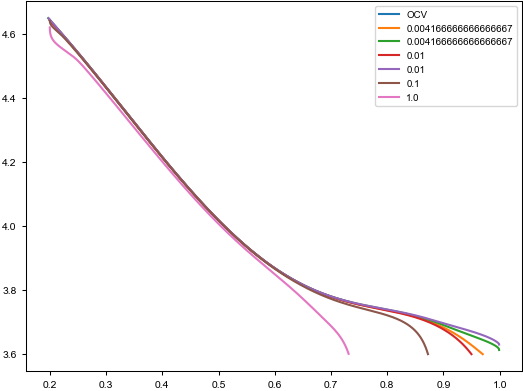

In [343]:
plt.plot(SOL,OCV,label="OCV")
for SOL,U3E,crate in zip(SOLs,U3Es,Crates):
    plt.plot(SOL,U3E,label=f"{crate}")
plt.legend()

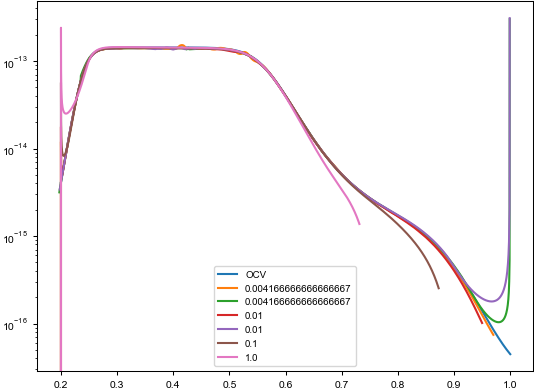

In [344]:
x = np.linspace(0.2,1,len(SOL))

plt.semilogy(x, Diffusion(x),label="OCV")
for SOL,D,crate in zip(SOLs,D_NMCs,Crates):
    plt.plot(SOL,D,label=f"{crate}")
plt.legend()

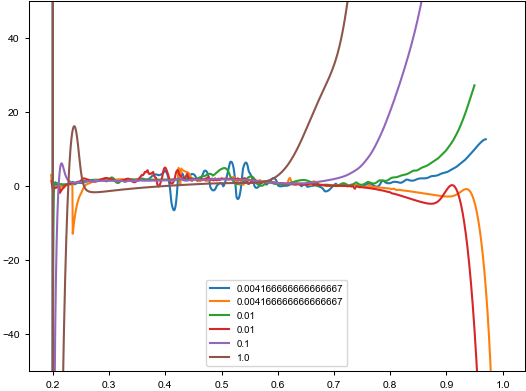

In [345]:
for SOL,D,crate in zip(SOLs,D_NMCs,Crates):
    plt.plot(SOL,(1-D/Diffusion(SOL))*100,label=f"{crate}")
plt.ylim([-50,50])
plt.legend()

In [346]:
Labels = ["-1/240 C","+1/240 C","-1/100 C","+1/100 C","-1/10 C","-1 C"]

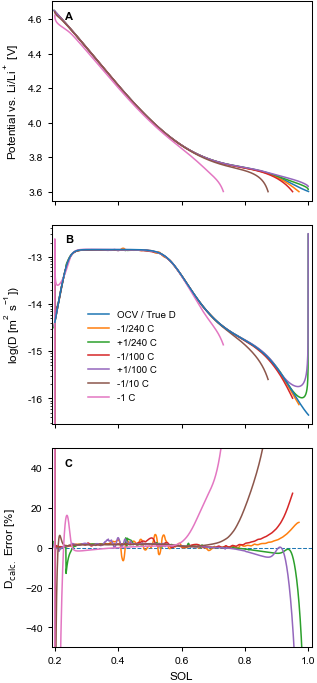

In [363]:
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter


# =============================================================================
# Publication-ready plotting configuration
# =============================================================================

# A4 page dimensions
A4_WIDTH = 210 / 25.4       # mm -> inch
A4_HEIGHT = 297 / 25.4      # mm -> inch

# "Right half of A4" / single-column journal-style figure width.
# Adjust to the exact journal template if required.
FIG_WIDTH = 3.25            # inch
FIG_HEIGHT = 7.1             # inch

# Output directory
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    # -------------------------------------------------------------------------
    # Typography
    # -------------------------------------------------------------------------
    "font.family": "Arial",
    "font.size": 8.0,

    "axes.labelsize": 8.5,
    "axes.titlesize": 8.5,

    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,

    "legend.fontsize": 7.0,

    # -------------------------------------------------------------------------
    # Axes / lines
    # -------------------------------------------------------------------------
    "axes.linewidth": 0.75,

    "xtick.major.width": 0.75,
    "ytick.major.width": 0.75,

    "xtick.minor.width": 0.55,
    "ytick.minor.width": 0.55,

    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,

    "xtick.minor.size": 1.8,
    "ytick.minor.size": 1.8,

    # -------------------------------------------------------------------------
    # Text rendering
    # -------------------------------------------------------------------------
    "mathtext.default": "regular",

    # Embed fonts appropriately
    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    # Keep text as editable text in SVG
    "svg.fonttype": 'path',

    # -------------------------------------------------------------------------
    # Figure saving
    # -------------------------------------------------------------------------
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})


# =============================================================================
# Figure
# =============================================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    gridspec_kw={
        "height_ratios": [1.0, 1.0, 1.0],
        "hspace": 0.12,
    },
)

ax_voltage, ax_diffusion, ax_error = axes


# =============================================================================
# Panel A — Potential
# =============================================================================

ax_voltage.plot(
    x, 
    OCV_NMC111_Charbonneau(x),
    label="OCV",
    linewidth=1.1,
    zorder=0,
)

for sol, u3e, crate in zip(SOLs, U3Es, Labels):
    ax_voltage.plot(
        sol,
        u3e,
        label=f"{crate}",
        linewidth=1.1,
    )

ax_voltage.set_ylabel(r"Potential vs. Li/Li$^+$ [V]")

# Panel label
ax_voltage.text(
    0.05,
    0.95,
    "A",
    transform=ax_voltage.transAxes,
    ha="left",
    va="top",
    fontweight="bold",
)

# Legend
"""ax_voltage.legend(
    loc="best",
    frameon=True,
    ncol=1,
    handlelength=2.2,
    borderaxespad=0.2,
    edgecolor='black',
)"""

ax_voltage.tick_params(
    axis="x",
    which="both",
    labelbottom=False,
)


# =============================================================================
# Panel B — Diffusion coefficient
# =============================================================================

x = np.linspace(0.2, 1.0, len(SOL))

ax_diffusion.semilogy(
    x,
    Diffusion(x),
    label="OCV / True D",
    linewidth=1.1,
    zorder=3,
)

for sol, diffusion, crate in zip(SOLs, D_NMCs, Labels):
    ax_diffusion.semilogy(
        sol,
        diffusion,
        label=f"{crate}",
        linewidth=1.1,
    )

ax_diffusion.set_ylabel(
    r"log(D [m$^2$ s$^{-1}$])"
)

ax_diffusion.text(
    0.05,
    0.95,
    "B",
    transform=ax_diffusion.transAxes,
    ha="left",
    va="top",
    fontweight="bold",
)

# Explicit logarithmic tick configuration
ax_diffusion.yaxis.set_major_locator(
    LogLocator(base=10.0, numticks=8)
)
ax_diffusion.set_yticklabels([-18,-17,-16,-15,-14,-13])
ax_diffusion.yaxis.set_minor_locator(
    LogLocator(
        base=10.0,
        subs=np.arange(2, 10) * 0.1,
        numticks=80,
    )
)
ax_diffusion.yaxis.set_minor_formatter(NullFormatter())

ax_diffusion.legend(
    loc='upper right', bbox_to_anchor=(0.5, 0.6),
    frameon=False,
    ncol=1,
    handlelength=2.2,
    borderaxespad=0.2,
)

ax_diffusion.tick_params(
    axis="x",
    which="both",
    labelbottom=False,
)


# =============================================================================
# Panel C — Relative error
# =============================================================================
ax_error.plot(
    [0,2],
    [0,0],
    label="0%",
    linewidth=0.75,
    linestyle="--",
    zorder=0,
)
for sol, diffusion, crate in zip(SOLs, D_NMCs, Labels):

    relative_error = (
        1.0 - diffusion / Diffusion(sol)
    ) * 100.0

    ax_error.plot(
        sol,
        relative_error,
        label=f"{crate}",
        linewidth=1.1,
    )


# Zero-error reference line
"""ax_error.axhline(
    0.0,
    linewidth=0.75,
    linestyle="--",
    zorder=0,
)"""


ax_error.set_ylim(-50, 50)

ax_error.set_ylabel(
    r"$D_{\mathrm{calc.}}$ Error [%]"
)

ax_error.set_xlabel(
    "SOL"
)

ax_error.text(
    0.05,
    0.95,
    "C",
    transform=ax_error.transAxes,
    ha="left",
    va="top",
    fontweight="bold",
)

"""ax_error.legend(
    loc="best",
    frameon=True,
    ncol=1,
    handlelength=2.2,
    borderaxespad=0.2,
)"""


# =============================================================================
# Common axis formatting
# =============================================================================

for ax in axes:

    # Remove unnecessary top/right borders
    # ax.spines["top"].set_visible(False)
    # ax.spines["right"].set_visible(False)

    # Consistent tick direction
    ax.tick_params(
        axis="both",
        which="both",
        direction="out",
        top=False,
        right=False,
    )

    # Keep a small horizontal margin
    ax.margins(x=0.02)


# Ensure the common x-axis covers the relevant SOL range
ax_error.set_xlim(
    min(0.19, np.nanmin(SOL)),
    max(1.01, np.nanmax(SOL)),
)


# =============================================================================
# Final layout
# =============================================================================

fig.subplots_adjust(
    left=0.18,
    right=0.98,
    bottom=0.075,
    top=0.985,
    hspace=0.12,
)


# =============================================================================
# Export
# =============================================================================

output_base = FIGURE_DIR / "NMC111_potential_diffusion_error"

# Vector format — recommended for journal submission
fig.savefig(
    output_base.with_suffix(".svg"),
    format="svg",
    dpi=600,
)

# Raster format — 600 DPI
fig.savefig(
    output_base.with_suffix(".png"),
    format="png",
    dpi=600,
)

plt.show()
plt.close(fig)